# EMIT → Landsat 9 OLI-2 band synthesis — NIR, pooled over the 4 invariant PICS

Synthesize the OLI-2 **NIR** band (`nir08`, 829-900 nm) from EMIT per-channel
radiance/reflectance, pooled over the **four invariant PICS** (Mauritania 1 excluded,
per the Landsat control), and compare the pooled drift to the real Landsat NIR band.

For each OLI-2 band with relative spectral response \(R_b(\lambda)\), the per-scene
synthesized value is the RSR-weighted integral over the EMIT channels:
\[ X^{\mathrm{EMIT}\to b} = \frac{\sum_i R_b(\lambda_i)\,X_i}{\sum_i R_b(\lambda_i)}. \]
We fit the shared-\(\gamma\) quasi-BRDF drift across the four sites (the same estimator
as the production BRDF analysis) with a stratified within-site bootstrap CI.

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from emit_pics.run_config import load_config
from emit_pics import paths, brdf_drift, landsat_brdf
from emit_pics.qc_gate import apply_qc_filter

cfg = load_config()
BAND = "nir08"
N_BOOT = 1000                              # bootstrap resamples (lower for speed)
roster, _, _ = brdf_drift.resolve_roster(cfg)
SITES = [s for s in roster if s not in set(cfg.brdf_drift_exclude_sites)]  # 4 invariant
print("invariant PICS:", SITES)
print("excluded from fit:", cfg.brdf_drift_exclude_sites)

invariant PICS: ['Libya_4', 'Libya_1', 'Algeria_3', 'Algeria_5']
excluded from fit: ['Mauritania_1']


## Step 1 — OLI-2 NIR relative spectral response (RSR)

72 points | span 829-900 nm


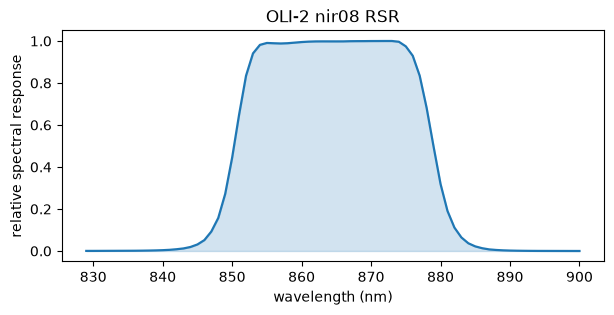

In [2]:
rsr_all = pd.read_csv(paths.DATA / "landsat" / "oli2_rsr" / "L9_OLI2_RSR_tidy.csv")
rsr = (rsr_all[rsr_all["band"] == BAND]
       .sort_values("wavelength_nm").reset_index(drop=True))
print(f"{len(rsr)} points | span {rsr.wavelength_nm.min():.0f}-{rsr.wavelength_nm.max():.0f} nm")

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(rsr.wavelength_nm, rsr.rsr, lw=1.6, color="tab:blue")
ax.fill_between(rsr.wavelength_nm, rsr.rsr, alpha=0.2, color="tab:blue")
ax.set(xlabel="wavelength (nm)", ylabel="relative spectral response", title=f"OLI-2 {BAND} RSR")
plt.show()

## Step 2 — Synthesize the band per scene, pooled over the 4 PICS
For each site: QC-surviving EMIT scenes, then the RSR-weighted integral for radiance
and reflectance. Pool into one table with `site`, `g = cos(SZA)`, and a common-clock
`t` (years since the earliest EMIT scene across all four sites).

In [3]:
def qc_scenes(site, patch):
    g = pd.read_csv(paths.geometry(site, patch))
    g["datetime"] = pd.to_datetime(g["datetime"])
    g["has_rfl"] = g["has_rfl"].astype(str).str.strip().str.lower().isin(["true", "1"])
    g = g.sort_values("datetime").reset_index(drop=True)
    g, _ = apply_qc_filter(g, paths.qc_sheet(site, patch), require_review=cfg.require_qc_review)
    return g[g["has_rfl"]].reset_index(drop=True)

def synth_scene(site, patch, ts, product):
    s = brdf_drift.scene_perchannel(site, patch, ts, product,
                                    earth_sun_normalize=cfg.earth_sun_normalize,
                                    e0_method=cfg.e0_method)
    if s is None:
        return np.nan
    x = s[f"median_{product}"].to_numpy(float)
    ww = np.interp(s["central_wl"].to_numpy(float), rsr.wavelength_nm, rsr.rsr,
                   left=0.0, right=0.0)
    m = (ww > 0) & np.isfinite(x)
    return float(np.sum(ww[m] * x[m]) / np.sum(ww[m]))

recs = []
for site in SITES:
    patch = roster[site]
    g = qc_scenes(site, patch)
    for _, r in g.iterrows():
        recs.append({"site": site, "patch": patch, "timestamp": r.timestamp,
                     "datetime": r.datetime, "sza": r.sza_mean,
                     "synth_rad": synth_scene(site, patch, r.timestamp, "rad"),
                     "synth_rfl": synth_scene(site, patch, r.timestamp, "rfl")})
emit = pd.DataFrame(recs).dropna().reset_index(drop=True)
emit["g"] = np.cos(np.radians(emit["sza"]))
emit["t"] = (emit["datetime"] - emit["datetime"].min()).dt.total_seconds() / (365.25 * 86400)
print(f"pooled EMIT scenes: {len(emit)}")
print(emit.groupby("site").size().rename("n_scenes"))

pooled EMIT scenes: 58
site
Algeria_3    14
Algeria_5    15
Libya_1      16
Libya_4      13
Name: n_scenes, dtype: int64


## Step 3 — EMIT channels under the band (example scene)

9 EMIT channels under the nir08 RSR (835-895 nm)


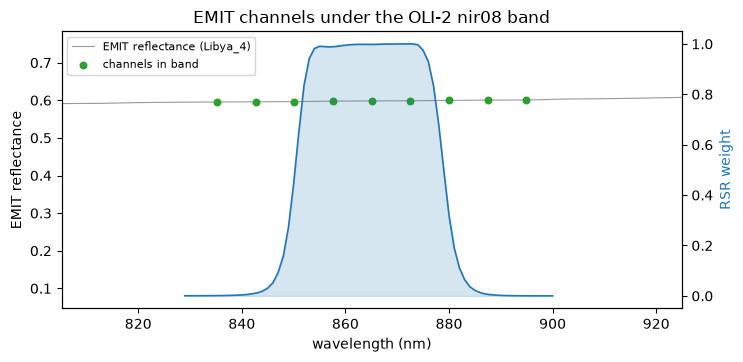

In [4]:
ex_site = SITES[0]; ex_patch = roster[ex_site]
ts0 = qc_scenes(ex_site, ex_patch).loc[0, "timestamp"]
spec0 = brdf_drift.scene_perchannel(ex_site, ex_patch, ts0, "rfl",
                                    earth_sun_normalize=cfg.earth_sun_normalize,
                                    e0_method=cfg.e0_method)
wl = spec0["central_wl"].to_numpy(float)
w = np.interp(wl, rsr.wavelength_nm, rsr.rsr, left=0.0, right=0.0)
inband = w > 1e-4
print(f"{int(inband.sum())} EMIT channels under the {BAND} RSR "
      f"({wl[inband].min():.0f}-{wl[inband].max():.0f} nm)")

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(wl, spec0["median_rfl"], color="0.6", lw=0.8, label=f"EMIT reflectance ({ex_site})")
ax.scatter(wl[inband], spec0["median_rfl"].to_numpy(float)[inband],
           color="tab:green", s=22, zorder=3, label="channels in band")
ax2 = ax.twinx()
ax2.fill_between(rsr.wavelength_nm, rsr.rsr, color="tab:blue", alpha=0.18)
ax2.plot(rsr.wavelength_nm, rsr.rsr, color="tab:blue", lw=1.2)
ax2.set_ylabel("RSR weight", color="tab:blue")
ax.set_xlim(wl[inband].min() - 30, wl[inband].max() + 30)
ax.set(xlabel="wavelength (nm)", ylabel="EMIT reflectance",
       title=f"EMIT channels under the OLI-2 {BAND} band")
ax.legend(loc="upper left", fontsize=8)
plt.show()

## Step 4 — Per-channel variability within the band (channel selection)
Scene-to-scene variability of each in-band channel, pooled across the four PICS. NIR is
clean; this diagnostic is what flags the high-variance channels in the coastal/blue
bands, where a variance/CI filter will be needed.

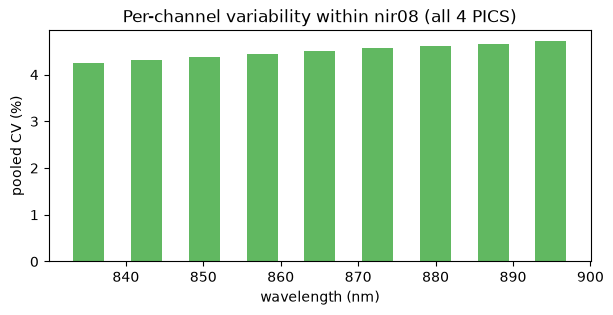

in-band CV: median 4.5%  max 4.7% @ 895 nm


In [5]:
mat = []
for _, r in emit.iterrows():
    s = brdf_drift.scene_perchannel(r.site, r.patch, r.timestamp, "rfl",
                                    earth_sun_normalize=cfg.earth_sun_normalize,
                                    e0_method=cfg.e0_method)
    mat.append(s["median_rfl"].to_numpy(float)[inband])
mat = np.array(mat)
inband_wl = wl[inband]
cv = 100 * np.nanstd(mat, axis=0) / np.nanmean(mat, axis=0)
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(inband_wl, cv, width=4, color="tab:green", alpha=0.75)
ax.set(xlabel="wavelength (nm)", ylabel="pooled CV (%)",
       title=f"Per-channel variability within {BAND} (all 4 PICS)")
plt.show()
print(f"in-band CV: median {np.median(cv):.1f}%  max {cv.max():.1f}% @ {inband_wl[cv.argmax()]:.0f} nm")

## Step 5 — Landsat NIR for the same 4 PICS
Pooled Landsat NIR TOA reflectance (nearest band to the target), with Mauritania 1
excluded to match the EMIT set.

In [6]:
ls_all, wl_by_site, T0_ls, notes = landsat_brdf.assemble_design_landsat(roster, cfg)
ls, dropped = brdf_drift.apply_drift_exclusion(ls_all, cfg)     # drop M1
print("Landsat band ~", {s: round(v) for s, v in wl_by_site.items()})
print(f"pooled Landsat scenes: {len(ls)} (dropped {dropped})")
print(ls.groupby("site").size().rename("n_scenes"))

Landsat band ~ {'Libya_4': 865, 'Libya_1': 865, 'Algeria_3': 865, 'Algeria_5': 865, 'Mauritania_1': 865}
pooled Landsat scenes: 258 (dropped ['Mauritania_1'])
site
Algeria_3    67
Algeria_5    63
Libya_1      59
Libya_4      69
Name: n_scenes, dtype: int64


## Step 6 — Pooled drift (shared γ) with bootstrap CI
Shared-γ quasi-BRDF fit across the four sites, with a stratified within-site bootstrap
95% CI, for the three series.

NIR pooled drift over 4 invariant PICS (%/yr):
                        gamma  ci_lo  ci_hi
EMIT synth radiance    -0.320 -0.703  0.073
EMIT synth reflectance -0.288 -0.683  0.094
Landsat NIR TOA        -0.116 -0.219 -0.004


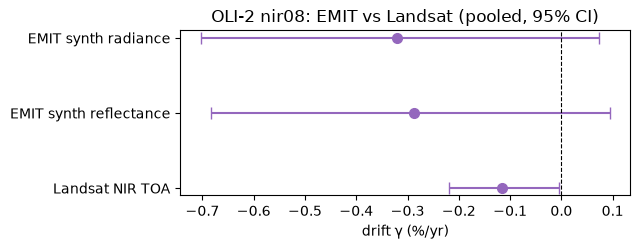

In [7]:
def pooled_gamma(df, value, n_boot=N_BOOT, seed=0):
    frame = df[["site", "g", "t"]].copy()
    frame["rho_rad"] = df[value].to_numpy(float)
    b = brdf_drift.bootstrap_joint_gamma(frame, "rad", n_boot, seed=seed)
    return 100 * b["gamma"], 100 * b["ci"][0], 100 * b["ci"][1]

results = {
    "EMIT synth radiance":    pooled_gamma(emit, "synth_rad"),
    "EMIT synth reflectance": pooled_gamma(emit, "synth_rfl"),
    "Landsat NIR TOA":        pooled_gamma(ls, "rho_toa"),
}
res = pd.DataFrame(results, index=["gamma", "ci_lo", "ci_hi"]).T.round(3)
print(f"NIR pooled drift over {len(SITES)} invariant PICS (%/yr):")
print(res)

fig, ax = plt.subplots(figsize=(6.5, 2.6))
y = np.arange(len(res))[::-1]
ax.errorbar(res["gamma"], y, xerr=[res["gamma"] - res["ci_lo"], res["ci_hi"] - res["gamma"]],
            fmt="o", color="tab:purple", capsize=4, lw=1.5, ms=7)
ax.axvline(0, color="k", lw=0.8, ls="--")
ax.set_yticks(y); ax.set_yticklabels(res.index)
ax.set(xlabel="drift γ (%/yr)", title=f"OLI-2 {BAND}: EMIT vs Landsat (pooled, 95% CI)")
plt.tight_layout(); plt.show()

## Step 7 — Per-site drift
Standalone single-site γ for each series, to see whether any one PICS drives the
pooled comparison.

In [ ]:
def site_gammas(df, value):
    out = {}
    for s, g in df.groupby("site"):
        frame = g[["g", "t"]].copy(); frame["site"] = s
        frame["rho_rad"] = g[value].to_numpy(float)
        out[s] = 100 * brdf_drift.fit_joint(frame, "rad")["gamma"]
    return out

persite = pd.DataFrame({
    "EMIT rad": site_gammas(emit, "synth_rad"),
    "EMIT rfl": site_gammas(emit, "synth_rfl"),
    "Landsat":  site_gammas(ls, "rho_toa"),
}).round(3)
print("Per-site NIR drift γ (%/yr):")
print(persite)

ax = persite.plot(kind="bar", figsize=(7.5, 3.2))
ax.axhline(0, color="k", lw=0.8)
ax.set(ylabel="drift γ (%/yr)", title=f"OLI-2 {BAND}: per-site drift")
plt.tight_layout(); plt.show()

## Summary & next steps
- NIR works pooled over the four invariant PICS, with EMIT (radiance & reflectance) and
  Landsat on the same sites and the same shared-γ estimator + bootstrap CI.
- **Generalise to all 7 bands:** wrap Steps 2-6 in a loop over the RSR bands, producing
  a 7-band EMIT-vs-Landsat drift comparison (radiance and reflectance).
- **Channel selection:** the Step-4 CV diagnostic plus the water-vapor mask will trim
  high-variance channels for the coastal/blue (and SWIR2-edge) bands before synthesis.